# Method E: a features-only network with mixup

Method E keeps the hand-made beam features of Method C (`learn.beam_features`) and drops the sequence branch. With tens of recordings and a few beams each, a recurrent model has more parameters than there are independent examples; a small dense network on 14 features has a chance. Three choices make it trainable on so little data:

- **Batch normalisation** after the first layer, so that features on very different scales (an amplitude around $10^{-2}$, a rate around $10^2$) do not have to be balanced by the first weights alone;
- **Dropout** (20 %), which keeps the network from relying on a single feature, such as the rate found by the signal processing chain;
- **Huber loss**, quadratic for small errors and linear for large ones, so that the few beams that point at the wrong person do not dominate training.

## Mixup for regression

Mixup (Zhang et al., ICLR 2018) trains on convex combinations of two examples and of their targets,
$$
\tilde{\mathbf x} = \lambda\,\mathbf x_i + (1-\lambda)\,\mathbf x_j,\qquad \tilde y = \lambda\,y_i + (1-\lambda)\,y_j,\qquad \lambda\sim\mathrm{Beta}(\alpha,\alpha).
$$
For classification it smooths the decision boundaries. For a rate it is a stronger assumption: that a beam whose features lie halfway between a beam at 12 and one at 30 breaths per minute would breathe at 21. That holds for features that vary smoothly with the rate (a spectral peak frequency) and not for others (an entropy, a kurtosis). With a small $\alpha$ most $\lambda$ are close to 0 or 1, so the mixed examples stay near the real ones; `learn.mixup` uses $\alpha = 0.2$ by default.

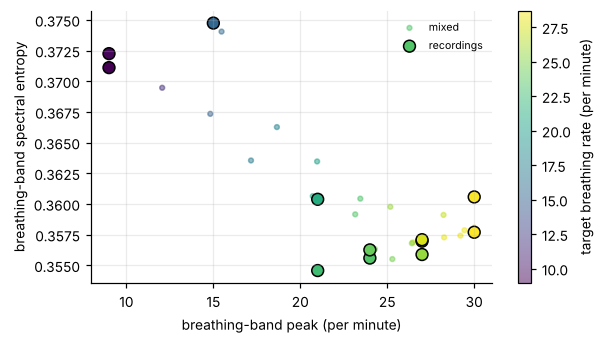

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
                     "axes.prop_cycle": plt.cycler(color=["#1b4965", "#c8553d", "#5c946e", "#8c6d9f"])})
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
from radar import cube, learn, simulate, vitals

# features of twelve short one-person recordings at different settings
rng = np.random.default_rng(0)
rows, rr_true = [], []
for k in range(12):
    rr, hr = rng.uniform(8, 32), rng.uniform(55, 130)
    x, tr = simulate.simulate([simulate.Person(1.8, 0, rr=rr, hr=hr)], duration=40, snr_db=18, seed=k)
    cfg = tr["config"]
    rp = cube.compensate_aop(cube.range_fft(x))
    z = rp[:, :, :, int(round(1.8 / cfg.range_resolution))].mean(axis=(1, 2))
    rows.append(learn.beam_features(z, cfg.frame_rate))
    rr_true.append(rr)
names = list(rows[0])
X = np.array([[r[n] for n in names] for r in rows])
y = np.array(rr_true)
Xm, ym = learn.mixup(X, y, alpha=0.2, n=4)

i, j = names.index("rr_peak_hz"), names.index("rr_entropy")
fig, ax = plt.subplots(figsize=(5.6, 3.2))
sc = ax.scatter(60 * Xm[:, i], Xm[:, j], c=ym, s=10, cmap="viridis", alpha=0.5, label="mixed")
ax.scatter(60 * X[:, i], X[:, j], c=y, s=60, cmap="viridis", edgecolors="k", label="recordings")
plt.colorbar(sc, label="target breathing rate (per minute)")
ax.set(xlabel="breathing-band peak (per minute)", ylabel="breathing-band spectral entropy")
ax.legend(fontsize=7, loc="upper right")
plt.tight_layout()

The mixed points lie on the segments between real recordings. Along the horizontal axis their colour follows the position, as it should for a peak frequency; along the vertical axis the entropy of a mixed point says nothing about the rate, and the network has to learn to ignore that direction.

The model itself, and the scaling of features and targets with training statistics only:

In [2]:
sc = learn.Scaler().fit(X, y)
model = learn.dense_model(X.shape[1])
model.summary(print_fn=lambda s: print(s) if s.strip() else None)
print("scaled target mean and std:", sc.y(y).mean().round(3), sc.y(y).std().round(3))

Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)           

The evaluation rules of Method C apply unchanged: split by recording (`learn.group_split`), read the error per clinical condition, and compare with the signal processing chain on the same recordings.